# 01 - Data EDA (UCI Adult)

Explores the features of the UCI Adult dataset to decide how they group into ontology concepts.
Section 7 states the resulting ontology, which the other notebooks use.

Input: `data/processed/adult.csv` (run `uv run project-acl-data` and `uv run project-acl-preprocess` first).

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats.contingency import association
from sklearn.feature_selection import mutual_info_classif

from project_acl.data import TARGET
from project_acl.preprocess import read

sns.set_theme(style="whitegrid", context="notebook")
FIG = Path("../docs/figures")
FIG.mkdir(exist_ok=True)
pd.set_option("display.precision", 3)

df = read()
NUM = [c for c in df.select_dtypes("number").columns if c != TARGET]
CAT = [c for c in df.select_dtypes(exclude="number").columns if c != "split"]
FEATS = NUM + CAT
print(df.shape, "| numeric:", NUM, "| categorical:", CAT)
df.head()

(48842, 16) | numeric: ['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week'] | categorical: ['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income,split
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,0,train
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,0,train
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,0,train
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,0,train
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,0,train


## 1. Overview: types, cardinality, missing values

In [2]:
overview = pd.DataFrame({
    "dtype": df[FEATS].dtypes.astype(str),
    "n_unique": df[FEATS].nunique(),
    "missing": df[FEATS].isna().sum(),
    "missing_%": 100 * df[FEATS].isna().mean(),
})
overview.sort_values("missing", ascending=False)

,dtype,n_unique,missing,missing_%
occupation,str,14,2809,5.751
workclass,str,8,2799,5.731
native-country,str,41,857,1.755
education-num,int64,16,0,0.000
age,int64,74,0,0.000
fnlwgt,int64,28523,0,0.000
hours-per-week,int64,96,0,0.000
capital-loss,int64,99,0,0.000
capital-gain,int64,123,0,0.000
education,str,16,0,0.000


In [3]:
# Do the missing values co-occur? workclass and occupation look like one "no job info" pattern.
miss = df[["workclass", "occupation", "native-country"]].isna()
print(pd.crosstab(miss["workclass"], miss["occupation"], rownames=["workclass NaN"], colnames=["occupation NaN"]))
print("\nworkclass of rows with occupation NaN but workclass present:")
print(df.loc[miss["occupation"] & ~miss["workclass"], "workclass"].value_counts())
print("\npositive rate | any missing:", df.loc[miss.any(axis=1), TARGET].mean().round(3),
      "| none missing:", df.loc[~miss.any(axis=1), TARGET].mean().round(3))

occupation NaN  False  True 
workclass NaN               
False           46033     10
True                0   2799

workclass of rows with occupation NaN but workclass present:
workclass
Never-worked    10
Name: count, dtype: int64

positive rate | any missing: 0.132 | none missing: 0.248


Missing values are few (< 6 % per column) and `workclass` / `occupation` are missing together
(the only exceptions are `Never-worked`, which has no occupation by definition).
Missing rows have a lower positive rate, so they are not missing at random. `encode()` already maps NaN to
all-zero dummies, so the rows can stay; no imputation is needed for the concept analysis.

## 2. Class balance

           n  positive_rate
split                      
test   16281          0.236
train  32561          0.241


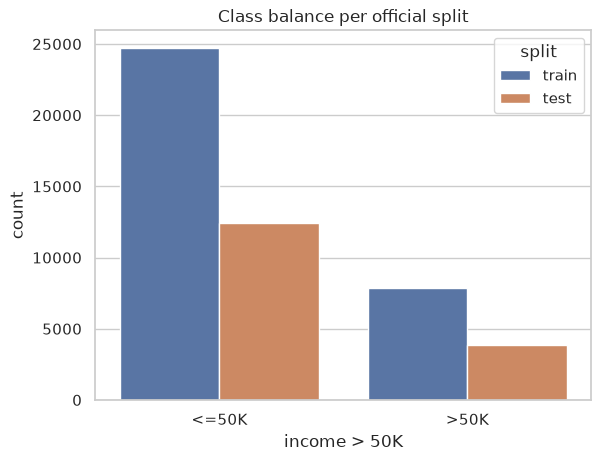

In [4]:
bal = df.groupby("split")[TARGET].agg(n="size", positive_rate="mean")
print(bal)
ax = sns.countplot(x=df[TARGET].map({0: "<=50K", 1: ">50K"}), hue=df["split"])
ax.set(xlabel="income > 50K", title="Class balance per official split");

About 24 % positive in both splits: imbalanced but not extreme, so `03_ensembles.ipynb` reports F1 next to
accuracy. The official split keeps the same ratio, so no stratification is needed.

## 3. Distributions

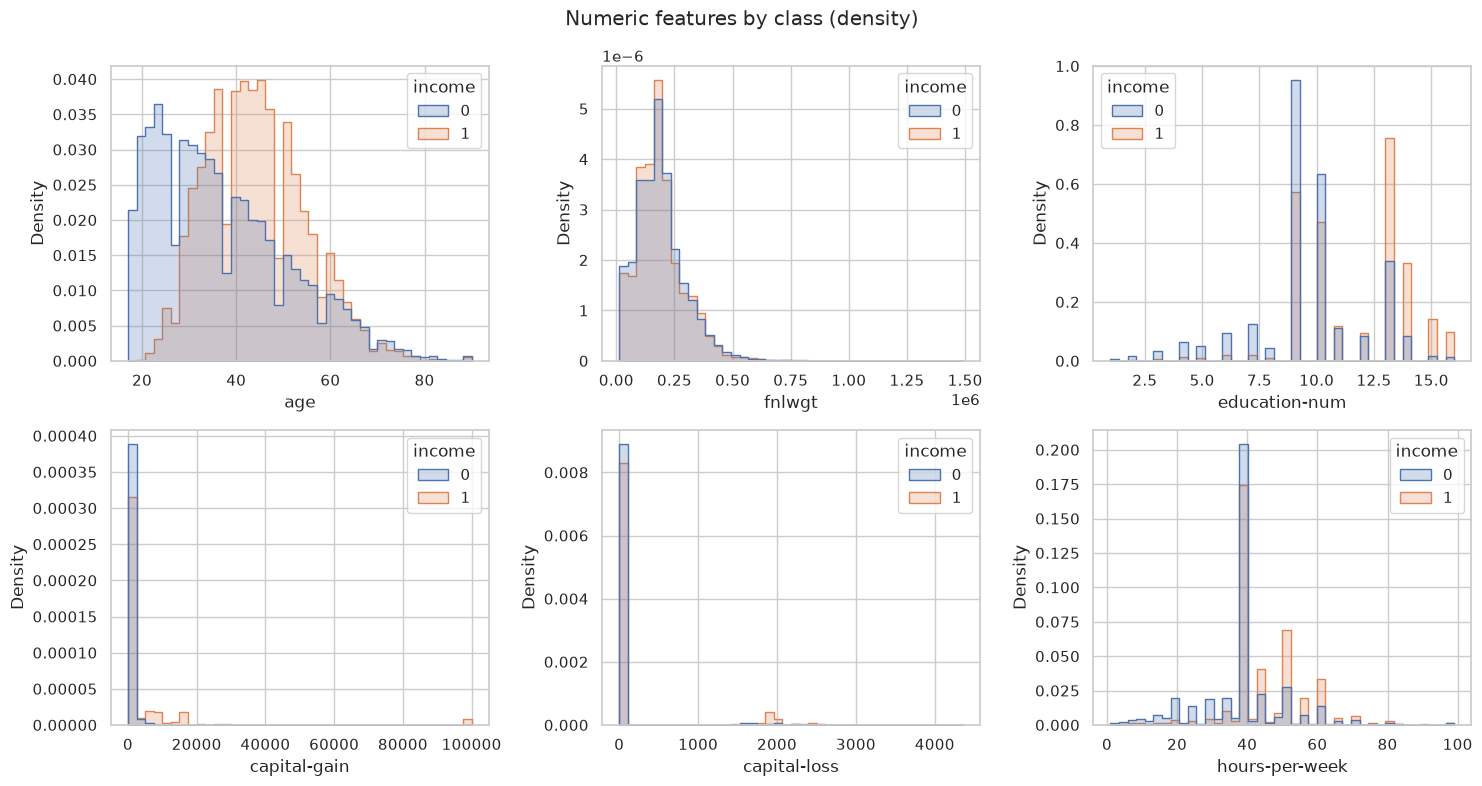

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, c in zip(axes.flat, NUM):
    sns.histplot(df, x=c, hue=TARGET, bins=40, ax=ax, element="step", stat="density", common_norm=False)
fig.suptitle("Numeric features by class (density)")
fig.tight_layout()

In [6]:
df[NUM].describe().T.assign(
    zero_share=(df[NUM] == 0).mean(),
    skew=df[NUM].skew(),
)

,count,mean,std,min,25%,50%,75%,max,zero_share,skew
age,48842.0,38.644,13.711,17.0,28.0,37.0,48.0,9.000e+01,0.000,0.558
fnlwgt,48842.0,189664.135,105604.025,12285.0,117550.5,178144.5,237642.0,1.490e+06,0.000,1.439
education-num,48842.0,10.078,2.571,1.0,9.0,10.0,12.0,1.600e+01,0.000,-0.317
capital-gain,48842.0,1079.068,7452.019,0.0,0.0,0.0,0.0,1.000e+05,0.917,11.895
capital-loss,48842.0,87.502,403.005,0.0,0.0,0.0,0.0,4.356e+03,0.953,4.570
hours-per-week,48842.0,40.422,12.391,1.0,40.0,40.0,45.0,9.900e+01,0.000,0.239


- `capital-gain` and `capital-loss` are almost always 0 (about 92 % and 95 %) and extremely skewed.
  They are rare but very strong signals; they belong together as the money-from-assets concept.
- `age` and `hours-per-week` separate the classes moderately (high earners are older and work longer).
- `fnlwgt` has nearly identical densities per class: it is a census sampling weight, not a property of the person.

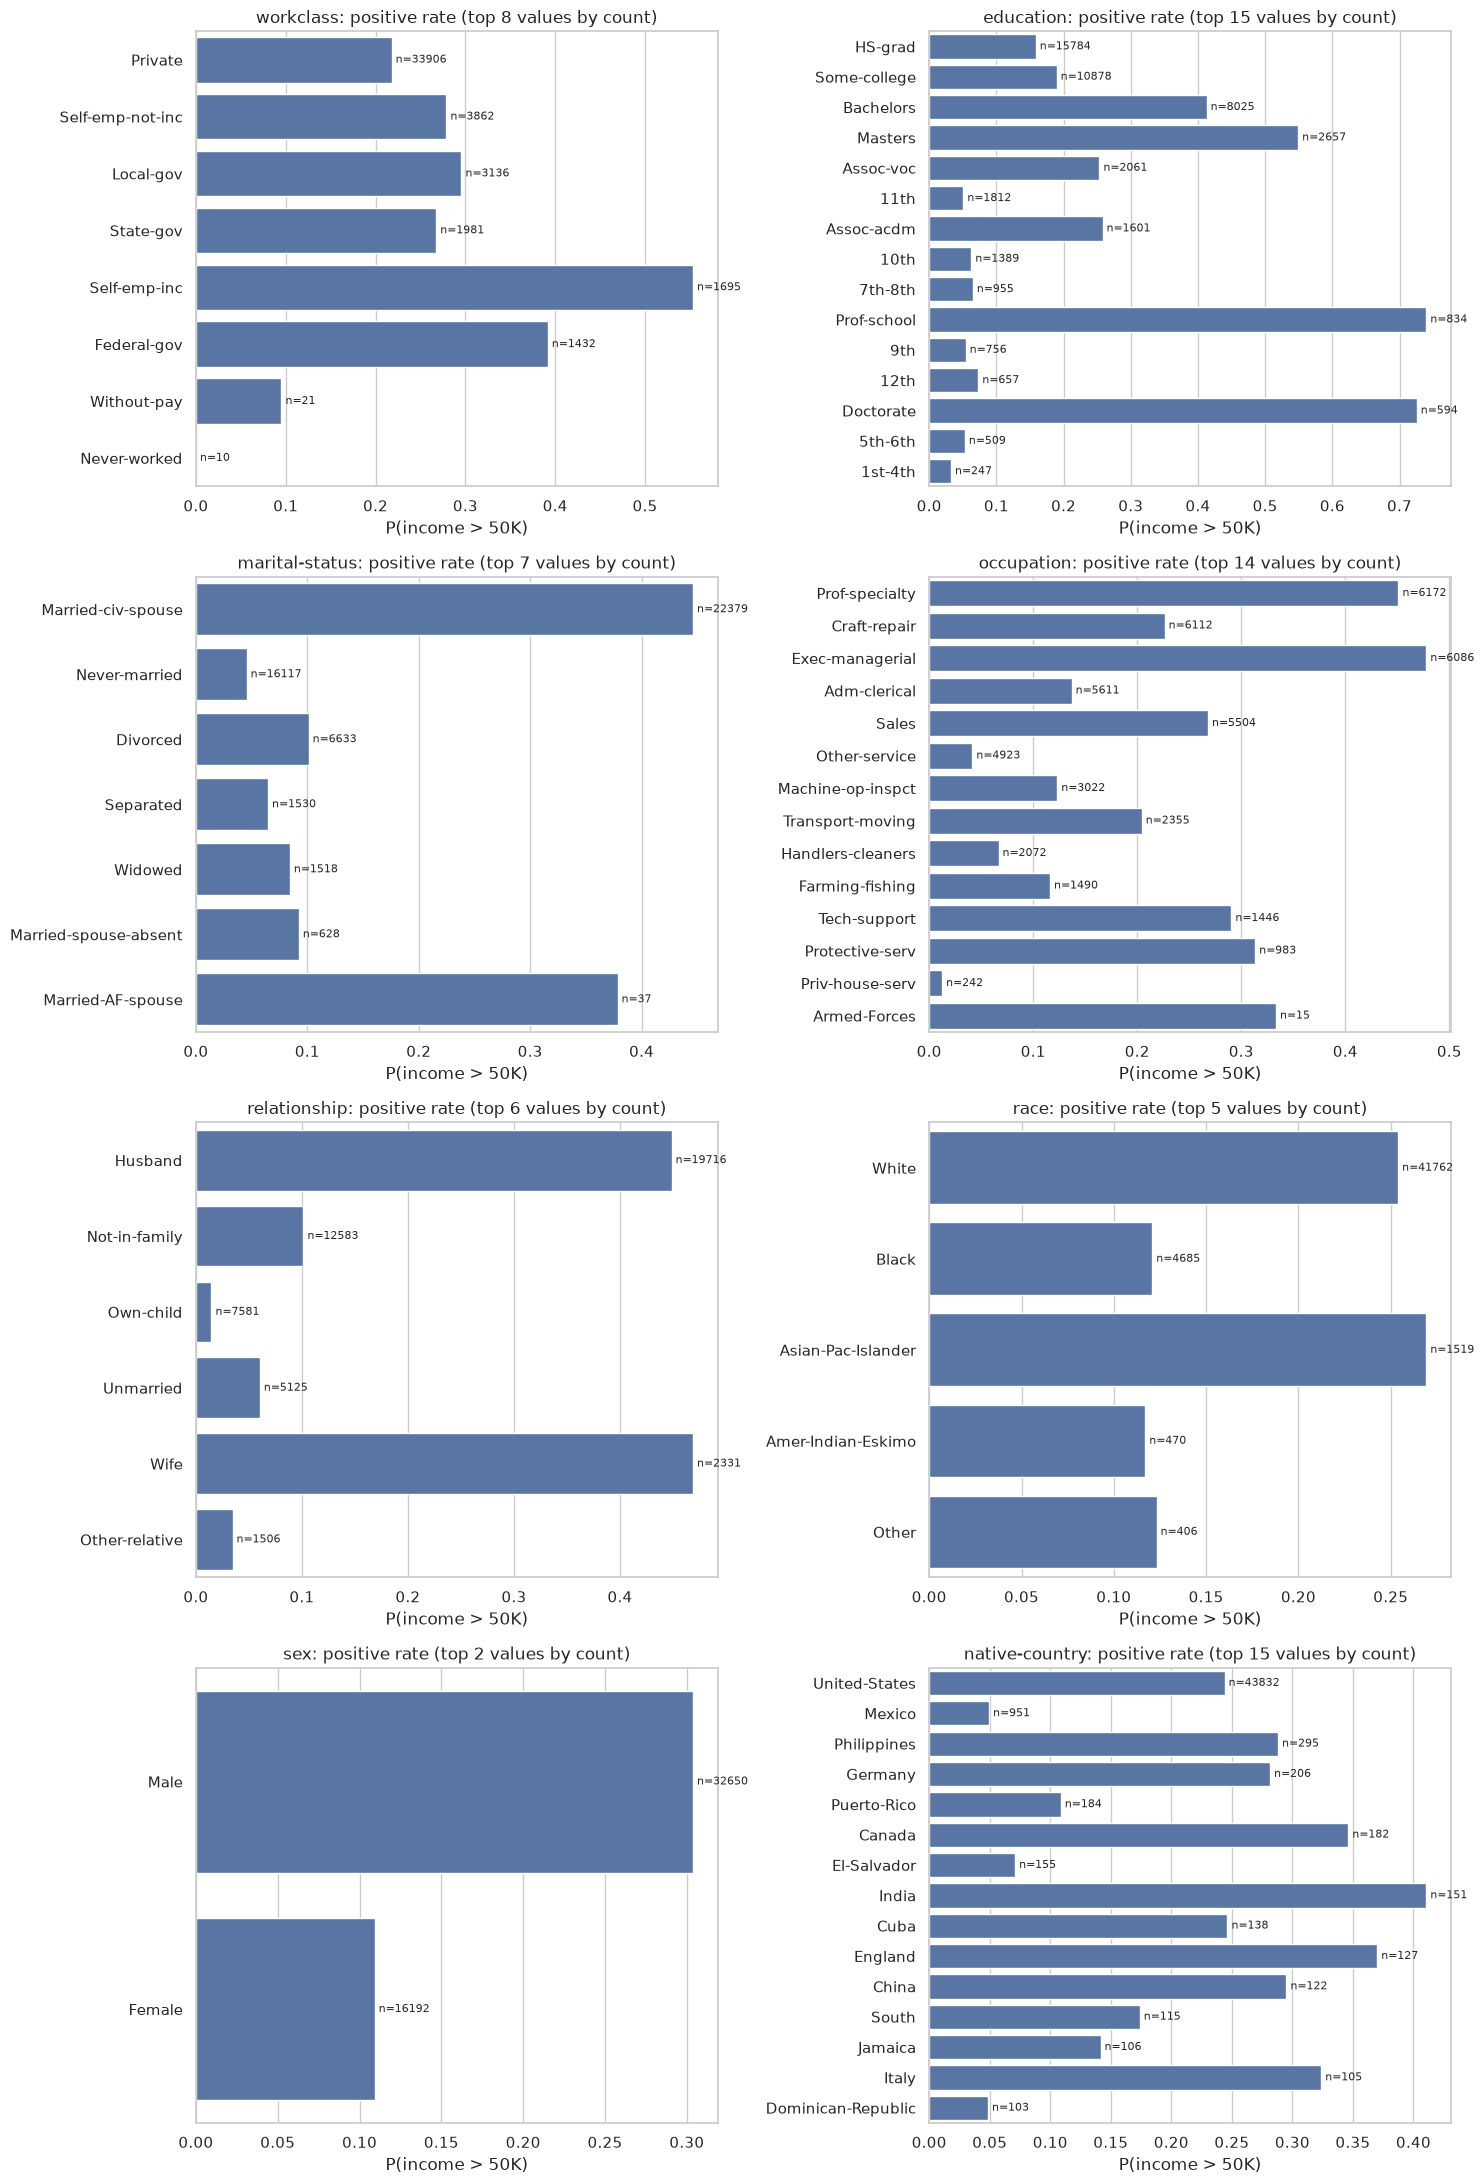

In [7]:
fig, axes = plt.subplots(4, 2, figsize=(15, 22))
for ax, c in zip(axes.flat, CAT):
    order = df[c].value_counts().index[:15]
    rate = df.groupby(c)[TARGET].mean().reindex(order)
    sns.barplot(x=rate.values, y=rate.index, ax=ax, color="C0")
    ax.set(title=f"{c}: positive rate (top {len(order)} values by count)", xlabel="P(income > 50K)", ylabel="")
    for i, n in enumerate(df[c].value_counts().loc[order]):
        ax.text(rate.iloc[i], i, f" n={n}", va="center", fontsize=8)
fig.tight_layout()

## 4. Associations between features

Cramer's V for every feature pair (numerics binned into deciles, or 0 vs quartiles of the non-zero values for
`capital-gain`/`capital-loss`, so all pairs use the same measure),
plus Pearson correlation for the numerics.

In [8]:
print(df[NUM].corr().round(2))

                 age  fnlwgt  education-num  capital-gain  capital-loss  \
age             1.00   -0.08           0.03          0.08          0.06   
fnlwgt         -0.08    1.00          -0.04         -0.00         -0.00   
education-num   0.03   -0.04           1.00          0.13          0.08   
capital-gain    0.08   -0.00           0.13          1.00         -0.03   
capital-loss    0.06   -0.00           0.08         -0.03          1.00   
hours-per-week  0.07   -0.01           0.14          0.08          0.05   

                hours-per-week  
age                       0.07  
fnlwgt                   -0.01  
education-num             0.14  
capital-gain              0.08  
capital-loss              0.05  
hours-per-week            1.00  


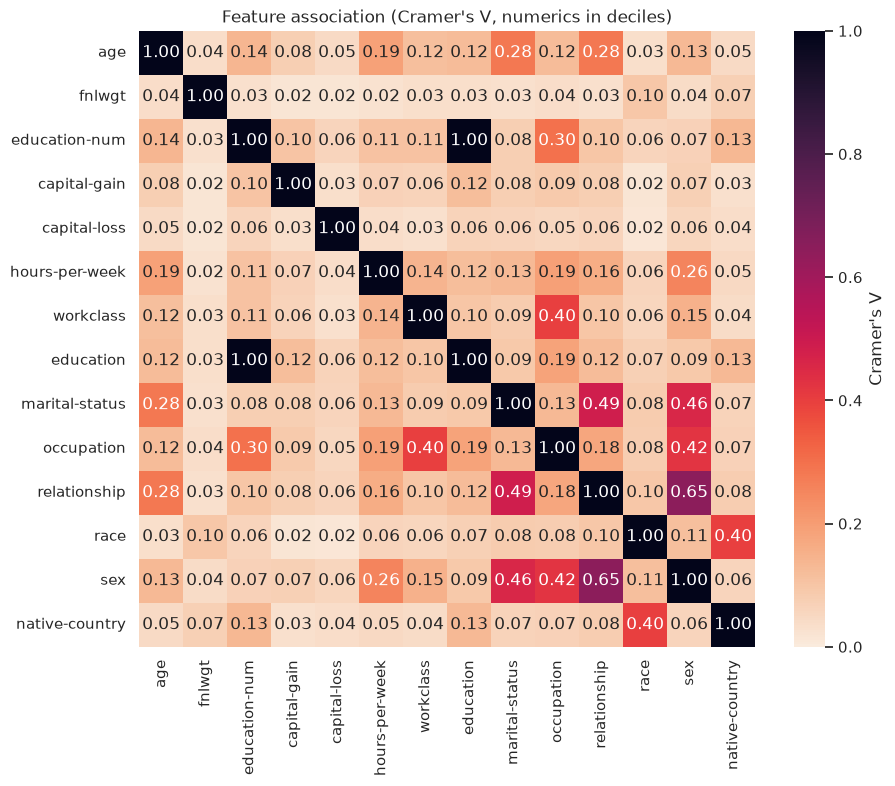

In [9]:
def binned(s):
    if s.name not in NUM:
        return s.fillna("NA")
    if (s == 0).mean() > 0.5:  # capital-gain/loss: deciles collapse on 0, so use 0 vs quartiles of the rest
        return pd.qcut(s[s > 0], 4).astype(str).reindex(s.index, fill_value="0")
    return pd.qcut(s, 10, duplicates="drop").astype(str)

# Cramer's V needs categories, so numerics are binned first; then fill the symmetric matrix pair by pair
B = df[FEATS].apply(binned)
V = pd.DataFrame(np.eye(len(FEATS)), FEATS, FEATS)
for i, a in enumerate(FEATS):
    for b in FEATS[i + 1:]:
        V.loc[a, b] = V.loc[b, a] = association(pd.crosstab(B[a], B[b]).to_numpy(), method="cramer")

plt.figure(figsize=(10, 8))
sns.heatmap(V, annot=True, fmt=".2f", cmap="rocket_r", vmin=0, vmax=1, square=True, cbar_kws={"label": "Cramer's V"})
plt.title("Feature association (Cramer's V, numerics in deciles)");
plt.gcf().savefig(FIG / "eda_cramers_v.png", dpi=200, bbox_inches="tight")

In [10]:
pairs = V.where(np.triu(np.ones(V.shape, bool), k=1)).stack().sort_values(ascending=False)
pairs.head(12).to_frame("cramers_v")

cramers_v
education-num  education           1.000
relationship   sex                 0.647
marital-status relationship        0.488
               sex                 0.459
occupation     sex                 0.424
race           native-country      0.402
workclass      occupation          0.400
education-num  occupation          0.297
age            relationship        0.284
               marital-status      0.283
hours-per-week sex                 0.256
               occupation          0.192

In [11]:
# relationship encodes marital status and sex at once
pd.crosstab(df["relationship"], [df["sex"], df["marital-status"]]).T

relationship                  Husband  Not-in-family  Other-relative  \
sex    marital-status                                                  
Female Divorced                     0           1799             115   
       Married-AF-spouse            0              0               1   
       Married-civ-spouse           1              8              94   
       Married-spouse-absent        0            117              18   
       Never-married                0           3025             355   
       Separated                    0            243              50   
       Widowed                      0            678              56   
Male   Divorced                     0           1829              66   
       Married-AF-spouse           12              0               0   
       Married-civ-spouse       19703             15             107   
       Married-spouse-absent        0            213              36   
       Never-married                0           4089             565   
       Separated                    0            394              29   
       Widowed                      0            173              14   

relationship                  Own-child  Unmarried  Wife  
sex    marital-status                                     
Female Divorced                     208       1879     0  
       Married-AF-spouse              1          0    23  
       Married-civ-spouse            72          0  2305  
       Married-spouse-absent         40        129     0  
       Never-married               2962        876     0  
       Separated                     77        561     0  
       Widowed                       16        483     0  
Male   Divorced                     247        490     0  
       Married-AF-spouse              0          0     0  
       Married-civ-spouse            71          0     3  
       Married-spouse-absent         21         54     0  
       Never-married               3788        457     0  
       Separated                     69        107     0  
       Widowed                        9         89     0

In [12]:
# education and education-num: same information?
df.groupby("education")["education-num"].agg(["min", "max", "size"]).sort_values("min")

,min,max,size
education,,,
Preschool,1,1,83
1st-4th,2,2,247
5th-6th,3,3,509
7th-8th,4,4,955
9th,5,5,756
10th,6,6,1389
11th,7,7,1812
12th,8,8,657
HS-grad,9,9,15784


Findings:
- `education` and `education-num` are **the same variable** (V = 1, a 1:1 mapping). They must share one concept.
  For training, keep both (the one-hot and the ordinal view carry the same information); attribution is
  summed per concept, so the duplication does not distort concept vectors.
- `relationship` and `marital-status` are strongly associated (V = 0.49): `Husband`/`Wife` imply married.
  `relationship` also encodes `sex` (`Husband` is male, `Wife` is female): V(relationship, sex) = 0.65,
  the strongest pair after the education duplicate.
  They form one **Family** concept; the link to `sex` is a known leak of a protected attribute through a proxy.
- `occupation` and `workclass` are associated (V = 0.40, partly shared missingness). `occupation` is also linked
  to `sex` (0.42) and `education-num` (0.30). They fit together as **Employment**.
- `race` and `native-country` are associated (V = 0.40, origin): both are demographic.
- `fnlwgt` has no notable association with any other feature (see heatmap row). Exclude it.
- `capital-gain` and `capital-loss` are nearly independent of each other (V = 0.03; a person rarely has both) and of
  everything else (V <= 0.12). Grouping them as **Finance** is a domain choice, not a statistical one.

## 5. Association with the target (mutual information)

,mutual_info,cramers_v_target
relationship,0.115,0.454
marital-status,0.109,0.448
capital-gain,0.083,0.352
education-num,0.065,0.355
age,0.065,0.319
education,0.064,0.366
occupation,0.064,0.350
hours-per-week,0.045,0.274
fnlwgt,0.039,0.032
capital-loss,0.036,0.197


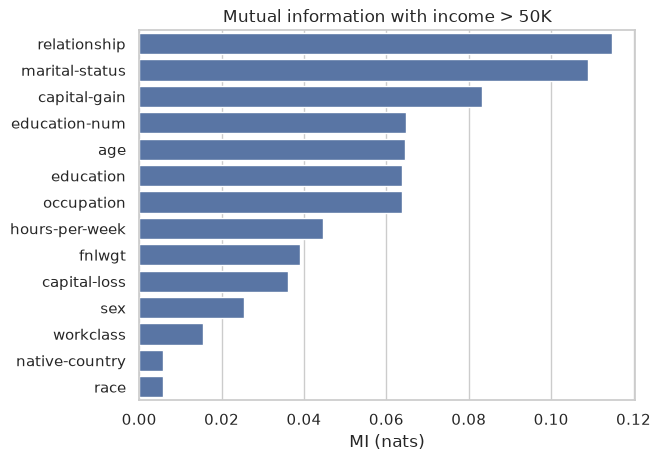

In [13]:
X = df[FEATS].copy()
for c in CAT:
    X[c] = X[c].fillna("NA").astype("category").cat.codes
mi = pd.Series(
    mutual_info_classif(X, df[TARGET], discrete_features=[c in CAT for c in FEATS], random_state=42),
    FEATS,
).sort_values(ascending=False)
target_v = pd.Series({c: association(pd.crosstab(B[c], df[TARGET]).to_numpy(), method="cramer") for c in FEATS})
rank = pd.DataFrame({"mutual_info": mi, "cramers_v_target": target_v}).sort_values("mutual_info", ascending=False)

ax = sns.barplot(x=rank["mutual_info"], y=rank.index, color="C0")
ax.set(title="Mutual information with income > 50K", xlabel="MI (nats)", ylabel="")
plt.gcf().savefig(FIG / "eda_mutual_information.png", dpi=200, bbox_inches="tight")
rank

The Family features (`relationship`, `marital-status`) are the strongest single signals, followed by
`capital-gain`, the Education pair, `age` and `occupation`. `race`, `native-country` and `workclass`
are weak. `fnlwgt` gets some MI only from noise in the continuous estimator; its Cramer's V with the target is near 0.

If the ensemble members follow the data, Family, Education and Finance should dominate their concept vectors
(checked in `04_concept_agreement.ipynb`).

## 6. Value-level grouping candidates

High-cardinality categoricals could get sub-concepts in the ontology. Groups are chosen from domain
meaning and checked against positive rate and size.

In [14]:
# Candidate value groups, chosen from domain meaning; group_table checks them against size and positive rate
OCCUPATION_GROUP = {
    "Exec-managerial": "WhiteCollar", "Prof-specialty": "WhiteCollar", "Tech-support": "WhiteCollar",
    "Sales": "WhiteCollar", "Adm-clerical": "WhiteCollar",
    "Craft-repair": "BlueCollar", "Machine-op-inspct": "BlueCollar", "Transport-moving": "BlueCollar",
    "Handlers-cleaners": "BlueCollar", "Farming-fishing": "BlueCollar",
    "Other-service": "Service", "Priv-house-serv": "Service", "Protective-serv": "Service",
    "Armed-Forces": "Service",
}
EDUCATION_GROUP = {  # by education-num: 1-8 below HS, 9-10 HS, 11-12 associate, 13+ degree
    **{e: "BelowHighSchool" for e in ["Preschool", "1st-4th", "5th-6th", "7th-8th", "9th", "10th", "11th", "12th"]},
    "HS-grad": "HighSchool", "Some-college": "HighSchool",
    "Assoc-voc": "Associate", "Assoc-acdm": "Associate",
    "Bachelors": "Bachelor", "Masters": "Postgraduate", "Prof-school": "Postgraduate", "Doctorate": "Postgraduate",
}
WORKCLASS_GROUP = {
    "Private": "Private", "Self-emp-not-inc": "SelfEmployed", "Self-emp-inc": "SelfEmployed",
    "Federal-gov": "Government", "State-gov": "Government", "Local-gov": "Government",
    "Without-pay": "NotWorking", "Never-worked": "NotWorking",
}
MARITAL_GROUP = {
    "Married-civ-spouse": "Married", "Married-AF-spouse": "Married",
    "Never-married": "NeverMarried",
    "Divorced": "PreviouslyMarried", "Separated": "PreviouslyMarried", "Widowed": "PreviouslyMarried",
    "Married-spouse-absent": "PreviouslyMarried",
}


def group_table(col, mapping):
    # per group: size, positive rate, and the lowest / highest positive rate of the values inside it
    assert set(df[col].dropna()) == set(mapping), f"{col}: mapping does not cover all values"
    g = df[col].map(mapping)
    out = df.groupby(g)[TARGET].agg(n="size", positive_rate="mean")
    within = df.groupby([g, df[col]])[TARGET].mean().groupby(level=0).agg(["min", "max"])
    return out.join(within.add_prefix("member_rate_")).sort_values("positive_rate")


for col, m in [("occupation", OCCUPATION_GROUP), ("education", EDUCATION_GROUP),
               ("workclass", WORKCLASS_GROUP), ("marital-status", MARITAL_GROUP)]:
    print(f"\n== {col} ==")
    print(group_table(col, m))


== occupation ==
                 n  positive_rate  member_rate_min  member_rate_max
occupation                                                         
Service       6163          0.084            0.012            0.333
BlueCollar   15051          0.169            0.067            0.226
WhiteCollar  24819          0.337            0.137            0.478

== education ==
                     n  positive_rate  member_rate_min  member_rate_max
education                                                              
BelowHighSchool   6408          0.057            0.012            0.073
HighSchool       26662          0.171            0.159            0.190
Associate         3662          0.255            0.253            0.258
Bachelor          8025          0.413            0.413            0.413
Postgraduate      4085          0.614            0.549            0.740

== workclass ==
                  n  positive_rate  member_rate_min  member_rate_max
workclass                          

In [15]:
nc = df["native-country"].value_counts(normalize=True)
print(nc.head(6).round(3))
print("\npositive rate US vs other:",
      df.groupby(df["native-country"].eq("United-States").map({True: "United-States", False: "Other/NA"}))[TARGET]
      .agg(["size", "mean"]))

native-country
United-States    0.913
Mexico           0.020
Philippines      0.006
Germany          0.004
Puerto-Rico      0.004
Canada           0.004
Name: proportion, dtype: float64

positive rate US vs other:                  size   mean
native-country              
Other/NA         5010  0.198
United-States   43832  0.244


- **occupation**: WhiteCollar / BlueCollar / Service separate the positive rate (0.34 / 0.17 / 0.08).
  `Adm-clerical` (0.14) is a low earner inside WhiteCollar and `Protective-serv` / `Armed-Forces` (about 0.31-0.33)
  are high inside Service, so the groups are not homogeneous, but they follow the standard labour-statistics split.
- **education**: grouping by `education-num` gives a monotone positive rate from BelowHighSchool to Postgraduate.
- **workclass**: Private / SelfEmployed / Government / NotWorking (0.22 / 0.36 / 0.31 / 0.07). SelfEmployed is mixed
  (`Self-emp-not-inc` 0.28 vs `Self-emp-inc` 0.55).
- **marital-status**: Married vs not is the real split (about 0.45 vs < 0.10); this mirrors `relationship`.
- **native-country**: over 90 % `United-States`, about 40 rare values. Not worth sub-concepts; keep the
  feature under Demographics and treat it as one unit (US 0.24 vs other 0.20 positive rate).

The value groups are not used as sub-concepts. Several of them are not homogeneous (`Adm-clerical` inside
WhiteCollar, `Self-emp-inc` inside SelfEmployed), and two ontology levels are enough to compare fine and coarse
concepts. The groups serve as evidence that each feature forms a meaningful leaf concept.

## 7. Ontology

```
Person
+-- Demographics
|   +-- Age                      age
|   +-- Origin                   race, native-country
|   +-- Sex                      sex
+-- Family
|   +-- MaritalStatus            marital-status
|   +-- HouseholdRole            relationship
+-- Education
|   +-- EducationLevel           education, education-num
+-- Employment
|   +-- Sector                   workclass
|   +-- Occupation               occupation
|   +-- WorkTime                 hours-per-week
+-- Finance
    +-- Capital                  capital-gain, capital-loss
ProtectedAttribute (separate view)   race, sex, relationship
(excluded)                           fnlwgt
```

| Choice | Reason |
|---|---|
| `education` + `education-num` in one leaf | 1:1 mapping (section 4); splitting them would make one concept look like two |
| Family split into `MaritalStatus` / `HouseholdRole` | both have the strongest MI with the target (section 5), so the leaf level can show which one members use |
| Employment split into `Sector` / `Occupation` / `WorkTime` | weak, medium and medium MI: different signals |
| Demographics split into `Age` / `Origin` / `Sex` | `race` and `native-country` are associated (V = 0.40); `age` and `sex` are separate signals |
| Finance kept as one leaf (`Capital`) despite V = 0.03 between its features | both describe income from assets; each alone is too small to be a concept |
| `relationship` in `ProtectedAttribute` | it gives away `sex` (`Husband`/`Wife`, V = 0.65), so it acts as a proxy |
| No value-level sub-concepts | the section 6 groups are not homogeneous; two levels are enough for the comparison |
| `fnlwgt` excluded | no association with any feature or the target (sections 3-5); it is a sampling weight by definition |

Levels used in the concept analysis:
- **Level 1 (top):** Demographics, Family, Education, Employment, Finance (5 concepts).
- **Level 2 (leaf):** Age, Origin, Sex, MaritalStatus, HouseholdRole, EducationLevel, Sector, Occupation,
  WorkTime, Capital (10 concepts). Every feature maps to exactly one leaf; one-hot columns inherit their source feature's leaf.
- **ProtectedAttribute** is a separate view, not a level: its features also keep their normal parents.